# DeepDNA drug-gene pipeline

**Business question:** Which genes affect the most medications, and how strong is the evidence behind those drug-gene pairs?

**Pipeline**
1. **Extract:** ask the API which genes it has, pull drug-gene data for every one, and store every raw JSON response in SQLite
2. **Transform:** flatten the raw JSON into clean tables (`drug_gene_pairs`, `phenotypes`)
3. **Snapshot:** every run is timestamped, so coverage can be tracked over time
4. **Variants:** for each gene, find its key variants (rsIDs) and pull each one from `/variants/{rsID}`
5. **Analyze:** data checks, charts, and findings

> Educational information only, not medical advice. The data comes from the DeepDNA API (deepdna.ai), which curates it from sources such as CPIC, DPWG, and ClinVar. Check the API terms before scheduling frequent calls.

## 1. Setup

In [1]:
import json
import re
import sqlite3
import time
from datetime import datetime, timezone
from urllib.parse import quote, unquote, urlparse

import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

BASE = "https://deepdna.ai/api/v1"
DB = "deepdna.db"
DELAY_SECONDS = 1.0  # pause between calls; the API is free and shared

# Which genes to pull:
#   True  = ask the API for its full gene list (GET /genes) on every run
#   False = use SEED_GENES below
DISCOVER_GENES = True
SEED_GENES = ["CYP2C19", "CYP2D6", "CYP2C9", "CYP3A5", "SLCO1B1",
              "TPMT", "NUDT15", "DPYD", "VKORC1", "UGT1A1"]  # note: SLCO1B1 has a letter O

# Possible field names for a gene symbol inside the /genes response.
# Edit this after running inspect_genes() if your response uses a different name.
GENE_SYMBOL_KEYS = ("symbol", "gene", "id", "name")

# Maps our code to the field names in the API response.
FIELD_MAP = {
    "drug_list_key": "pairs",         # key holding the list of drug-gene pairs
    "drug_name_key": "drug",          # drug name inside each pair
    "guideline_key": "guideline",     # guideline source, e.g. "CPIC" or "DPWG; FDA label"
    "level": "level",                 # evidence level, e.g. "CPIC A"
    "summary": "summary",             # plain-language summary of the guidance
    "phenotypes": "phenotypes",       # list of metabolizer phenotypes (can be null)
    "sources": "sources",             # list of citations for the pair (can be null)
}

/Users/kenjoves/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 2. Pipeline functions

In [2]:
def now():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")


PHENOTYPE_PATTERN = re.compile(r"^\s*(?P<name>[^(:]+?)\s*(?:\((?P<code>[^)]*)\))?\s*:\s*(?P<desc>.*)$")
SOURCE_LABEL_KEYS = ("name", "title", "source", "citation", "label", "id")
SOURCE_URL_KEYS = ("url", "link", "href")


def as_list(value):
    """Always return a list: None -> [], a single value -> [value]."""
    if value is None:
        return []
    return value if isinstance(value, list) else [value]


def parse_source(item):
    """Turn one source (a string or an object) into (label, url)."""
    if isinstance(item, str):
        return item, (item if item.startswith("http") else None)
    if isinstance(item, dict):
        label = next((str(item[k]) for k in SOURCE_LABEL_KEYS if item.get(k)), None)
        url = next((str(item[k]) for k in SOURCE_URL_KEYS if item.get(k)), None)
        return (label or url or json.dumps(item)), url
    return str(item), None


def parse_phenotype(text):
    """Split 'Poor metabolizer (PM): two no-function alleles' into (name, code, description)."""
    if not isinstance(text, str):
        return None, None, None
    m = PHENOTYPE_PATTERN.match(text)
    if not m:
        return text.strip(), None, None
    return m["name"].strip(), (m["code"] or "").strip() or None, m["desc"].strip() or None


def init_db(con):
    con.executescript("""
    CREATE TABLE IF NOT EXISTS raw_responses (
        id INTEGER PRIMARY KEY,
        run_ts TEXT, endpoint TEXT, status INTEGER, body TEXT
    );
    CREATE TABLE IF NOT EXISTS drug_gene_pairs (
        run_ts TEXT, gene TEXT, drug TEXT, guideline TEXT,
        level TEXT, summary TEXT
    );
    CREATE TABLE IF NOT EXISTS phenotypes (
        run_ts TEXT, gene TEXT, drug TEXT, phenotype TEXT,
        phenotype_name TEXT, code TEXT, description TEXT
    );
    CREATE TABLE IF NOT EXISTS pair_sources (
        run_ts TEXT, gene TEXT, drug TEXT, source TEXT, url TEXT
    );
    CREATE TABLE IF NOT EXISTS variants (
        run_ts TEXT, rsid TEXT, gene TEXT, name TEXT, alleles TEXT,
        effect TEXT, frequency TEXT
    );
    CREATE TABLE IF NOT EXISTS variant_sources (
        run_ts TEXT, rsid TEXT, gene TEXT, source TEXT, url TEXT
    );
    CREATE TABLE IF NOT EXISTS run_summary (
        run_ts TEXT, genes_found INTEGER, genes_missing INTEGER, pairs INTEGER,
        genes_listed INTEGER, variants INTEGER
    );
    """)
    # Older databases were created without some columns; add them if missing.
    for table, col, kind in (("drug_gene_pairs", "level", "TEXT"),
                             ("drug_gene_pairs", "summary", "TEXT"),
                             ("run_summary", "genes_listed", "INTEGER"),
                             ("run_summary", "variants", "INTEGER"),
                             ("phenotypes", "phenotype_name", "TEXT"),
                             ("phenotypes", "code", "TEXT"),
                             ("phenotypes", "description", "TEXT")):
        try:
            con.execute(f"ALTER TABLE {table} ADD COLUMN {col} {kind}")
        except sqlite3.OperationalError:
            pass  # column already exists
    con.commit()


def fetch(endpoint):
    """GET one endpoint with simple retries. Returns (status, parsed_json_or_None)."""
    url = f"{BASE}/{endpoint}"
    for attempt in range(3):
        try:
            r = requests.get(url, timeout=20)
            if r.status_code in (200, 404):
                return r.status_code, r.json()
            time.sleep(2 ** attempt)
        except (requests.RequestException, ValueError):
            time.sleep(2 ** attempt)
    return 0, None


def parse_gene_list(body):
    """Pull gene symbols out of a /genes response, whether items are strings or objects."""
    if not body:
        return []
    if isinstance(body, list):
        items = body
    else:  # use the first list-valued field (skips the "meta" block)
        items = next((v for v in body.values() if isinstance(v, list)), [])
    symbols = []
    for item in items:
        if isinstance(item, str):
            symbols.append(item)
        elif isinstance(item, dict):
            for key in GENE_SYMBOL_KEYS:
                if item.get(key):
                    symbols.append(str(item[key]))
                    break
    return sorted(set(symbols))


def inspect_genes():
    """Print what GET /genes returns, so you can check parse_gene_list() against it."""
    status, body = fetch("genes")
    print("status:", status)
    print(json.dumps(body, indent=2)[:2500])
    print("\nParsed symbols:", parse_gene_list(body))


def get_genes(con, run_ts):
    """Return the list of genes to pull, and store the raw /genes response."""
    if not DISCOVER_GENES:
        return list(SEED_GENES)
    status, body = fetch("genes")
    con.execute(
        "INSERT INTO raw_responses (run_ts, endpoint, status, body) VALUES (?,?,?,?)",
        (run_ts, "genes", status, json.dumps(body)),
    )
    genes = parse_gene_list(body) if status == 200 else []
    if not genes:
        con.commit()
        raise RuntimeError(
            "Could not read a gene list from GET /genes. Run inspect_genes() to see the "
            "response, then adjust GENE_SYMBOL_KEYS or set DISCOVER_GENES = False."
        )
    if isinstance(body, dict) and body.get("count") not in (None, len(genes)):
        print(f"WARNING: API says count={body.get('count')} but parsed {len(genes)} genes "
              "(the list may be paginated)")
    print(f"API lists {len(genes)} genes")
    return genes


def extract(con, run_ts):
    """Store the gene list, then call /pgx/{gene} for every gene. Returns the list of genes."""
    genes = get_genes(con, run_ts)
    for gene in genes:
        endpoint = f"pgx/{quote(gene)}"
        status, body = fetch(endpoint)
        con.execute(
            "INSERT INTO raw_responses (run_ts, endpoint, status, body) VALUES (?,?,?,?)",
            (run_ts, endpoint, status, json.dumps(body)),
        )
        print(f"{endpoint}: {status}")
        time.sleep(DELAY_SECONDS)
    con.commit()
    return genes


def transform(con, run_ts, genes_listed=None):
    """Flatten this run's raw responses into clean tables."""
    rows = con.execute(
        "SELECT endpoint, status, body FROM raw_responses "
        "WHERE run_ts = ? AND endpoint LIKE 'pgx/%'", (run_ts,)
    ).fetchall()
    found = missing = pairs = 0

    for endpoint, status, body in rows:
        gene = unquote(endpoint.split("/", 1)[1])
        if status != 200:
            missing += 1
            continue
        found += 1
        data = json.loads(body) or {}
        items = data.get(FIELD_MAP["drug_list_key"]) or []

        # data-quality check: the API reports how many pairs it returned
        if data.get("count") != len(items):
            print(f"WARNING: {gene} count={data.get('count')} but parsed {len(items)}")

        for item in items:
            if not isinstance(item, dict):
                continue
            drug = item.get(FIELD_MAP["drug_name_key"])
            con.execute(
                "INSERT INTO drug_gene_pairs (run_ts, gene, drug, guideline, level, summary) "
                "VALUES (?,?,?,?,?,?)",
                (run_ts, gene, drug,
                 item.get(FIELD_MAP["guideline_key"]),
                 item.get(FIELD_MAP["level"]),
                 item.get(FIELD_MAP["summary"])),
            )
            for ph in as_list(item.get(FIELD_MAP["phenotypes"])):
                ph_name, ph_code, ph_desc = parse_phenotype(ph)
                con.execute(
                    "INSERT INTO phenotypes "
                    "(run_ts, gene, drug, phenotype, phenotype_name, code, description) "
                    "VALUES (?,?,?,?,?,?,?)",
                    (run_ts, gene, drug, as_text(ph), ph_name, ph_code, ph_desc),
                )
            for src in as_list(item.get(FIELD_MAP["sources"])):
                label, url = parse_source(src)
                con.execute(
                    "INSERT INTO pair_sources (run_ts, gene, drug, source, url) VALUES (?,?,?,?,?)",
                    (run_ts, gene, drug, label, url),
                )
            pairs += 1

    con.execute(
        "INSERT INTO run_summary (run_ts, genes_found, genes_missing, pairs, genes_listed) "
        "VALUES (?,?,?,?,?)",
        (run_ts, found, missing, pairs, genes_listed),
    )
    con.commit()
    print(f"genes listed={genes_listed}, with /pgx data={found}, "
          f"without={missing}, drug-gene pairs={pairs}")

## 2b. Variant functions

For each gene we call `GET /genes/{gene}`, collect the rsIDs of its key variants, then call `GET /variants/{rsID}` for each one. The response field names below are **guesses**: run the check cell after this section and edit `VARIANT_MAP` to match the real names.

In [3]:
# Field names inside a /variants/{rsID} response (edit after running inspect_variant()).
VARIANT_MAP = {
    "name": "name",                      # star-allele or common name, e.g. "*2"
    "alleles": "alleles",                # reference / variant alleles
    "effect": "functional_effect",       # functional effect of the variant
    "frequency": "population_frequency", # population frequency note
    "sources": "sources",                # citations
}

RSID_PATTERN = re.compile(r"\brs\d+\b", re.IGNORECASE)


def as_text(value):
    """SQLite can't store lists or dicts, so turn them into JSON text."""
    if value is None or isinstance(value, (str, int, float)):
        return value
    return json.dumps(value)


def find_rsids(body):
    """Find every rsID anywhere in a response, whatever its structure."""
    return sorted(set(m.lower() for m in RSID_PATTERN.findall(json.dumps(body or {}))))


def inspect_gene_detail(gene="CYP2C19"):
    """Print the raw GET /genes/{gene} response and the rsIDs found in it."""
    status, body = fetch(f"genes/{quote(gene)}")
    print("status:", status)
    print(json.dumps(body, indent=2)[:2500])
    print("\nrsIDs found:", find_rsids(body))


def inspect_variant(rsid="rs4244285"):
    """Print the raw GET /variants/{rsid} response so you can check VARIANT_MAP."""
    status, body = fetch(f"variants/{rsid}")
    print("status:", status)
    print(json.dumps(body, indent=2)[:2500])


def store_raw(con, run_ts, endpoint, status, body):
    con.execute(
        "INSERT INTO raw_responses (run_ts, endpoint, status, body) VALUES (?,?,?,?)",
        (run_ts, endpoint, status, json.dumps(body)),
    )


def extract_variants(con, run_ts, genes):
    """Fetch GET /genes/{gene} for each gene, then GET /variants/{rsID} for every rsID found.
    Only stores raw responses; transform_variants() builds the tables from them."""
    rsids = set()
    for gene in genes:
        endpoint = f"genes/{quote(gene)}"
        status, body = fetch(endpoint)
        store_raw(con, run_ts, endpoint, status, body)
        time.sleep(DELAY_SECONDS)
        if status == 200:
            rsids.update(find_rsids(body))
    print(f"Found {len(rsids)} unique rsIDs across {len(genes)} genes")

    for rsid in sorted(rsids):
        endpoint = f"variants/{rsid}"
        status, body = fetch(endpoint)
        store_raw(con, run_ts, endpoint, status, body)
        time.sleep(DELAY_SECONDS)
    con.commit()
    return len(rsids)


def transform_variants(con, run_ts):
    """Build the variants and variant_sources tables from the stored raw responses."""
    rows = con.execute(
        "SELECT endpoint, status, body FROM raw_responses WHERE run_ts = ? "
        "AND (endpoint LIKE 'genes/%' OR endpoint LIKE 'variants/%')", (run_ts,)
    ).fetchall()

    rsid_genes, records = {}, {}   # rsID -> genes it was found under; rsID -> its record
    for endpoint, status, body in rows:
        if status != 200:
            continue
        kind, _, rest = endpoint.partition("/")
        body = json.loads(body)
        if kind == "genes":
            for rsid in find_rsids(body):
                rsid_genes.setdefault(rsid, set()).add(unquote(rest))
        elif isinstance(body, dict):
            # some APIs wrap the record in a "variant" key; handle both layouts
            records[rest] = body.get("variant") if isinstance(body.get("variant"), dict) else body

    if not rsid_genes:
        print("No raw variant data for this run.")
        return 0

    stored = 0
    for rsid, gene_set in sorted(rsid_genes.items()):
        data = records.get(rsid)
        if data is None:
            print(f"variants/{rsid}: no data (skipped)")
            continue
        for gene in sorted(gene_set):
            con.execute(
                "INSERT INTO variants (run_ts, rsid, gene, name, alleles, effect, frequency) "
                "VALUES (?,?,?,?,?,?,?)",
                (run_ts, rsid, gene,
                 as_text(data.get(VARIANT_MAP["name"])),
                 as_text(data.get(VARIANT_MAP["alleles"])),
                 as_text(data.get(VARIANT_MAP["effect"])),
                 as_text(data.get(VARIANT_MAP["frequency"]))),
            )
            for src in as_list(data.get(VARIANT_MAP["sources"])):
                label, url = parse_source(src)
                con.execute(
                    "INSERT INTO variant_sources (run_ts, rsid, gene, source, url) VALUES (?,?,?,?,?)",
                    (run_ts, rsid, gene, label, url),
                )
            stored += 1

    con.execute("UPDATE run_summary SET variants = ? WHERE run_ts = ?", (stored, run_ts))
    con.commit()
    print(f"variants stored={stored}")
    return stored


def reprocess(con, run_ts):
    """Rebuild every derived table for one run from its stored raw responses (no API calls).
    Use this after changing FIELD_MAP, VARIANT_MAP, or the table layout."""
    prev = con.execute("SELECT genes_listed FROM run_summary WHERE run_ts = ?", (run_ts,)).fetchone()
    has_raw_variants = con.execute(
        "SELECT COUNT(*) FROM raw_responses WHERE run_ts = ? AND endpoint LIKE 'variants/%'",
        (run_ts,)).fetchone()[0] > 0

    tables = ["drug_gene_pairs", "phenotypes", "pair_sources", "run_summary"]
    if has_raw_variants:
        tables += ["variants", "variant_sources"]
    for table in tables:
        con.execute(f"DELETE FROM {table} WHERE run_ts = ?", (run_ts,))

    transform(con, run_ts, prev[0] if prev else None)
    if has_raw_variants:
        transform_variants(con, run_ts)

### Check the gene list first

Run this once to see what `GET /genes` returns and confirm the symbols were parsed correctly. If the "Parsed symbols" list is empty or wrong, adjust `GENE_SYMBOL_KEYS` in the setup cell.

In [4]:
inspect_genes()

status: 200
{
  "count": 17,
  "genes": [
    {
      "symbol": "MTHFR",
      "name": "5,10-Methylenetetrahydrofolate reductase",
      "category": "nutrigenomics",
      "summary": "MTHFR encodes the enzyme that converts dietary folate into its biologically active form, 5-methyltetrahydrofolate. Two common variants, C677T (rs1801133) and A1298C (rs1801131), reduce enzyme activity. Carrying either variant is common and, with adequate dietary folate, almost always clinically silent.",
      "url": "https://deepdna.ai/api/v1/genes/MTHFR"
    },
    {
      "symbol": "COMT",
      "name": "Catechol-O-methyltransferase",
      "category": "nutrigenomics",
      "summary": "COMT encodes the enzyme that methylates and inactivates catecholamines (dopamine, epinephrine and norepinephrine) and is the main route for clearing dopamine in the prefrontal cortex. The Val158Met variant (rs4680), sometimes called the warrior/worrier SNP, changes enzyme activity roughly four-fold between genotypes. Th

### Check the variant responses

Run this once. Look at the rsIDs found for CYP2C19 and at the fields in the variant response, then edit `VARIANT_MAP` so each value points at a real field name.

In [5]:
inspect_gene_detail("CYP2C19")
print("\n" + "-" * 60 + "\n")
inspect_variant("rs4244285")

status: 200
{
  "gene": {
    "symbol": "CYP2C19",
    "name": "Cytochrome P450 Family 2 Subfamily C Member 19",
    "protein": "Cytochrome P450 2C19",
    "ncbi_gene_id": "1557",
    "locus": "10q23.33",
    "summary": "CYP2C19 is a hepatic cytochrome P450 enzyme that activates the antiplatelet prodrug clopidogrel and clears proton-pump inhibitors, several antidepressants, diazepam and the antifungal voriconazole. Poor metabolizers convert little clopidogrel to its active form, a difference linked to higher rates of stent thrombosis and recurrent cardiovascular events and the basis of the drug's FDA boxed warning. Star-allele haplotypes map to poor, intermediate, normal, rapid and ultra-rapid metabolizer phenotypes.",
    "function": "CYP2C19 performs oxidative metabolism on a focused but high-stakes set of drugs. For clopidogrel it acts as an activator: clopidogrel is an inactive prodrug and CYP2C19 catalyzes a key step converting it into the active metabolite that blocks platelet ag

## 3. Run the pipeline

Each run adds a new timestamped snapshot. Re-running is safe: earlier runs are kept. A gene the API lists but has no `/pgx` data for (a 404) counts toward `genes_missing`; that usually means it has no drug pairs, not that something broke.

In [6]:
con = sqlite3.connect(DB)
try:
    init_db(con)
    ts = now()
    genes = extract(con, ts)
    transform(con, ts, len(genes))
    extract_variants(con, ts, genes)
    transform_variants(con, ts)
except Exception:
    con.rollback()
    raise
finally:
    con.close()

API lists 17 genes
pgx/APOE: 200
pgx/BRCA1: 200
pgx/COMT: 200
pgx/CYP2C19: 200
pgx/CYP2C9: 200
pgx/CYP2D6: 200
pgx/CYP3A5: 200
pgx/CYP4F2: 200
pgx/DPYD: 200
pgx/G6PD: 200
pgx/HFE: 404
pgx/MTHFR: 200
pgx/NUDT15: 200
pgx/SLCO1B1: 200
pgx/TPMT: 200
pgx/UGT1A1: 200
pgx/VKORC1: 200
genes listed=17, with /pgx data=16, without=1, drug-gene pairs=84
Found 41 unique rsIDs across 17 genes
variants/rs115232898: no data (skipped)
variants stored=41


### Optional: remove old debugging runs

Set `CLEAN_OLD_RUNS = True` and run this cell **once** to keep only the newest run. Leave it `False` once you start collecting a real history.

In [7]:
CLEAN_OLD_RUNS = False

if CLEAN_OLD_RUNS:
    con = sqlite3.connect(DB)
    newest = con.execute("SELECT MAX(run_ts) FROM run_summary").fetchone()[0]
    for table in ("raw_responses", "drug_gene_pairs", "phenotypes", "pair_sources",
                  "variants", "variant_sources", "run_summary"):
        con.execute(f"DELETE FROM {table} WHERE run_ts != ?", (newest,))
    con.commit()
    con.close()
    print("Kept only the run from", newest)

### Optional: rebuild the tables from stored raw data

After changing the table layout or a field map, set `REPROCESS_LATEST = True` and run this cell once. It rebuilds every derived table for the newest run from the raw responses already saved in the database, so it makes **no API calls**. Set it back to `False` afterward.

In [8]:
REPROCESS_LATEST = False

if REPROCESS_LATEST:
    con = sqlite3.connect(DB)
    newest = con.execute("SELECT MAX(run_ts) FROM run_summary").fetchone()[0]
    reprocess(con, newest)
    con.close()

## 4. Data checks

In [9]:
con = sqlite3.connect(DB)

summary = pd.read_sql("SELECT * FROM run_summary ORDER BY run_ts", con)
latest_ts = summary.run_ts.max()
display(summary)

pairs = pd.read_sql("SELECT * FROM drug_gene_pairs", con)
phen = pd.read_sql("SELECT * FROM phenotypes", con)
latest = pairs[pairs.run_ts == latest_ts].copy()
latest_ph = phen[phen.run_ts == latest_ts]

print(f"\nLatest run: {latest_ts}")
print("Rows:", len(latest))
print("\nMissing values per column:")
print(latest.isna().sum())
print("\nDuplicate gene/drug rows (should be 0):",
      latest.duplicated(["gene", "drug"]).sum())

failed = pd.read_sql(
    "SELECT endpoint, status, body FROM raw_responses "
    "WHERE run_ts = ? AND endpoint LIKE 'pgx/%' AND status != 200",
    con, params=(latest_ts,))
print("\nGenes listed by the API with no /pgx data in latest run:", len(failed))
for _, row in failed.iterrows():
    err = (json.loads(row.body) or {}).get("error") or {}
    print(" ", row.endpoint, row.status, "| hint:", err.get("hint"))

variants = pd.read_sql("SELECT * FROM variants WHERE run_ts = ?", con, params=(latest_ts,))
print(f"\nVariants stored in latest run: {len(variants)}")
if len(variants):
    print("Missing values per column (all missing = wrong VARIANT_MAP):")
    print(variants.isna().sum())

print()
for table in ("pair_sources", "phenotypes", "variant_sources"):
    n = con.execute(f"SELECT COUNT(*) FROM {table} WHERE run_ts = ?", (latest_ts,)).fetchone()[0]
    print(f"{table}: {n} rows in latest run")

con.close()

,run_ts,genes_found,genes_missing,pairs,genes_listed,variants
0,2026-11-15T17:27:28+00:00,9,1,0,NaN,NaN
1,2026-11-15T17:34:00+00:00,9,1,57,NaN,NaN
2,2026-11-15T17:39:48+00:00,10,0,64,NaN,NaN
3,2026-11-15T17:43:10+00:00,9,1,57,NaN,NaN
4,2026-11-15T17:44:14+00:00,9,1,57,NaN,NaN
5,2026-11-15T17:45:16+00:00,9,1,57,NaN,NaN
6,2026-11-15T17:52:01+00:00,9,1,57,NaN,NaN
7,2026-11-15T17:56:56+00:00,9,0,57,NaN,NaN
8,2026-11-15T18:13:06+00:00,10,0,64,NaN,NaN
9,2026-11-15T18:20:28+00:00,16,1,84,17.0,NaN



Latest run: 2026-11-15T18:43:01+00:00
Rows: 84

Missing values per column:
run_ts       0
gene         0
drug         0
guideline    4
level        8
summary      0
dtype: int64

Duplicate gene/drug rows (should be 0): 0

Genes listed by the API with no /pgx data in latest run: 1
  pgx/HFE 404 | hint: HFE is in the knowledge base but has no drug–gene pairs curated yet.

Variants stored in latest run: 41
Missing values per column (all missing = wrong VARIANT_MAP):
run_ts        0
rsid          0
gene          0
name          0
alleles       0
effect       41
frequency    41
sources      41
dtype: int64

pair_sources: 346 rows in latest run
phenotypes: 373 rows in latest run
variant_sources: 107 rows in latest run


## 5. Analysis

All charts use the **latest run only**, so repeated runs don't double-count.

### How much of the API has drug data?

In [10]:
con = sqlite3.connect(DB)
status = pd.read_sql(
    "SELECT endpoint, status FROM raw_responses WHERE run_ts = ? AND endpoint LIKE 'pgx/%'",
    con, params=(latest_ts,))
con.close()

status["gene"] = status.endpoint.str.split("/", n=1).str[1]
status["has_pairs"] = status.gene.isin(set(latest.gene))

print(f"{len(status)} genes pulled, {status.has_pairs.sum()} with drug pairs")
print("Genes with no drug pairs:", sorted(status.loc[~status.has_pairs, "gene"]))

17 genes pulled, 16 with drug pairs
Genes with no drug pairs: ['HFE']


### Which genes have the most drug pairs?

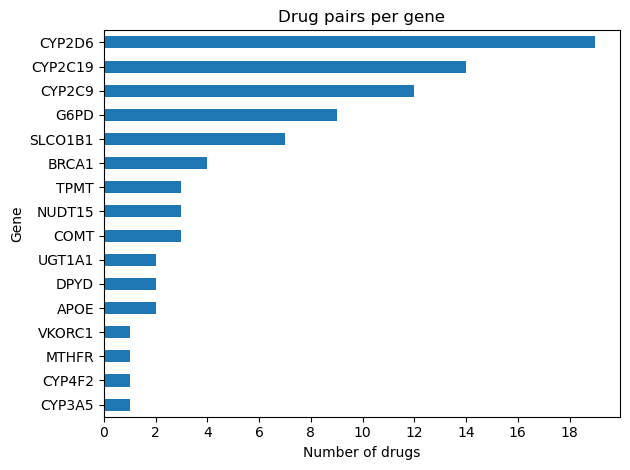

gene
CYP2D6     19
CYP2C19    14
CYP2C9     12
G6PD        9
SLCO1B1     7
BRCA1       4
COMT        3
NUDT15      3
TPMT        3
APOE        2
DPYD        2
UGT1A1      2
CYP3A5      1
CYP4F2      1
MTHFR       1
VKORC1      1
dtype: int64

In [11]:
per_gene = latest.groupby("gene").size().sort_values()
ax = per_gene.plot.barh(title="Drug pairs per gene")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Number of drugs")
ax.set_ylabel("Gene")
plt.tight_layout()
plt.show()
per_gene.sort_values(ascending=False)

### Where does the guidance come from?

Some rows list several sources in one string (for example `"DPWG; FDA label"`), so we split them into flags. One pair can count toward more than one source.

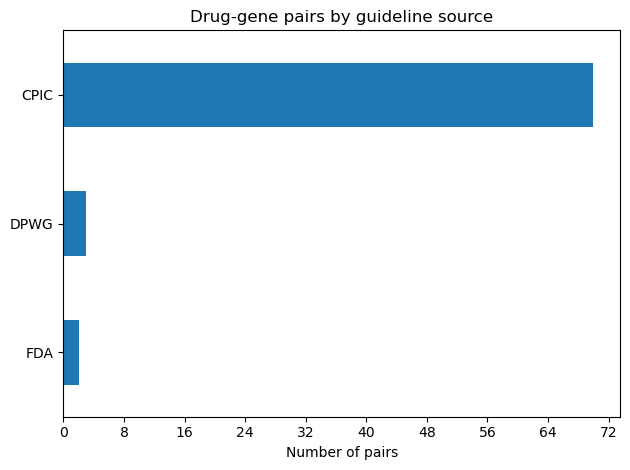

FDA      2
DPWG     3
CPIC    70
dtype: int64

In [12]:
for name in ("CPIC", "DPWG", "FDA"):
    latest[name] = latest.guideline.str.contains(name, na=False)

sources = latest[["CPIC", "DPWG", "FDA"]].sum().sort_values()
ax = sources.plot.barh(title="Drug-gene pairs by guideline source")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Number of pairs")
plt.tight_layout()
plt.show()
sources

### How strong is the evidence?

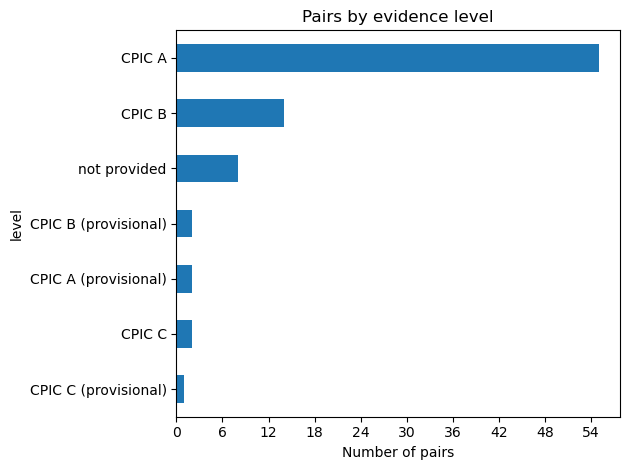

level
CPIC C (provisional)     1
CPIC C                   2
CPIC A (provisional)     2
CPIC B (provisional)     2
not provided             8
CPIC B                  14
CPIC A                  55
Name: count, dtype: int64

In [13]:
levels = latest.level.fillna("not provided").value_counts().sort_values()
ax = levels.plot.barh(title="Pairs by evidence level")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Number of pairs")
plt.tight_layout()
plt.show()
levels

### Which drugs depend on more than one gene?

In [14]:
multi = (latest.groupby("drug")
         .agg(n_genes=("gene", "nunique"),
              genes=("gene", lambda s: ", ".join(sorted(set(s)))))
         .query("n_genes > 1")
         .sort_values(["n_genes", "drug"], ascending=[False, True]))
multi

,n_genes,genes
drug,,
warfarin,3,"CYP2C9, CYP4F2, VKORC1"
amitriptyline,2,"CYP2C19, CYP2D6"
azathioprine,2,"NUDT15, TPMT"
clomipramine,2,"CYP2C19, CYP2D6"
doxepin,2,"CYP2C19, CYP2D6"
fluvastatin,2,"CYP2C9, SLCO1B1"
imipramine,2,"CYP2C19, CYP2D6"
mercaptopurine,2,"NUDT15, TPMT"
thioguanine,2,"NUDT15, TPMT"


### Look up one pair

Shows the summary and metabolizer phenotypes for any gene-drug pair in the latest run.

In [15]:
def show_pair(gene, drug):
    row = latest[(latest.gene == gene) & (latest.drug == drug)]
    if row.empty:
        print(f"No pair found for {gene} / {drug}")
        return
    r = row.iloc[0]
    print(f"{gene} / {drug}   [{r.guideline} | {r.level}]\n")
    print(r.summary, "\n")
    for p in latest_ph[(latest_ph.gene == gene) & (latest_ph.drug == drug)].phenotype:
        print(" -", p)

show_pair("CYP2C19", "clopidogrel")

CYP2C19 / clopidogrel   [CPIC | CPIC A]

Prodrug activated by CYP2C19. CPIC 2022 recommends an alternative antiplatelet (prasugrel or ticagrelor) for poor and intermediate metabolizers undergoing PCI for acute coronary syndromes. FDA boxed warning about reduced effectiveness in poor metabolizers. 

 - Poor metabolizer (PM): two no-function alleles (e.g. *2/*2, *2/*3)
 - Intermediate metabolizer (IM): one no-function allele with one normal or increased-function allele (e.g. *1/*2, *2/*17)
 - Normal metabolizer (NM): two normal-function alleles (*1/*1)
 - Rapid metabolizer (RM): one normal and one increased-function allele (*1/*17)
 - Ultra-rapid metabolizer (UM): two increased-function alleles (*17/*17)


### Variants

41 gene/variant rows in the latest run


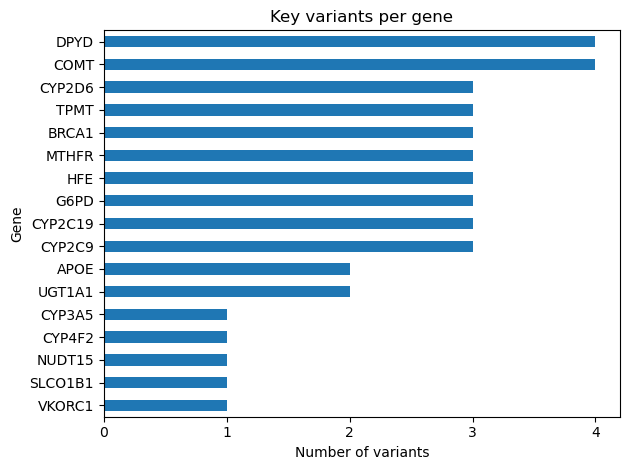

In [16]:
con = sqlite3.connect(DB)
variants = pd.read_sql("SELECT * FROM variants WHERE run_ts = ?", con, params=(latest_ts,))
con.close()

print(len(variants), "gene/variant rows in the latest run")

if variants.empty:
    print("No variants stored. Run inspect_gene_detail() and inspect_variant() and check VARIANT_MAP.")
else:
    per_gene_var = variants.groupby("gene").size().sort_values()
    ax = per_gene_var.plot.barh(title="Key variants per gene")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("Number of variants")
    ax.set_ylabel("Gene")
    plt.tight_layout()
    plt.show()

Drug pairs and variants side by side, per gene:

In [17]:
overview = (pd.DataFrame({"drug_pairs": latest.groupby("gene").size(),
                          "variants": variants.groupby("gene").size()})
            .fillna(0).astype(int)
            .sort_values(["drug_pairs", "variants"], ascending=False))
overview

,drug_pairs,variants
gene,,
CYP2D6,19,3
CYP2C19,14,3
CYP2C9,12,3
G6PD,9,3
SLCO1B1,7,1
BRCA1,4,3
COMT,3,4
TPMT,3,3
NUDT15,3,1


### Look up one variant

In [18]:
def show_variant(rsid):
    rows = variants[variants.rsid == rsid.lower()]
    if rows.empty:
        print(f"No variant found for {rsid}")
        return
    for _, r in rows.iterrows():
        print(f"{r.rsid}  ({r.gene})  {r['name']}")
        print("  alleles:  ", r.alleles)
        print("  effect:   ", r.effect)
        print("  frequency:", r.frequency)

show_variant("rs4244285")

rs4244285  (CYP2C19)  *2 (c.681G>A)
  alleles:   Plus strand, GRCh37 (as in 23andMe raw data): G reference, A variant, which defines *2. CYP2C19 is on the plus strand, so the letters match the gene. Copies of A at this one position are not a metabolizer status: that needs the other CYP2C19 variants and phasing.
  effect:    None
  frequency: None


### Sources and phenotypes

In [19]:
con = sqlite3.connect(DB)
pair_sources = pd.read_sql("SELECT * FROM pair_sources WHERE run_ts = ?", con, params=(latest_ts,))
variant_sources = pd.read_sql("SELECT * FROM variant_sources WHERE run_ts = ?", con, params=(latest_ts,))
phen = pd.read_sql("SELECT * FROM phenotypes WHERE run_ts = ?", con, params=(latest_ts,))
con.close()


def top_sources(df, n=10):
    """Count sources, grouped by website when a URL exists and by the source text otherwise."""
    if df.empty:
        return pd.Series(dtype=int)
    domain = df["url"].map(lambda u: urlparse(u).netloc if isinstance(u, str) else None)
    return domain.fillna(df["source"]).value_counts().head(n)


print(f"Drug-gene pair sources: {len(pair_sources)} rows, {pair_sources.source.nunique()} unique")
display(top_sources(pair_sources))
print(f"\nVariant sources: {len(variant_sources)} rows, {variant_sources.source.nunique()} unique")
display(top_sources(variant_sources))

Drug-gene pair sources: 346 rows, 88 unique


url
pubmed.ncbi.nlm.nih.gov    114
cpicpgx.org                 77
www.pharmgkb.org            72
www.pharmvar.org            44
dailymed.nlm.nih.gov        17
www.ncbi.nlm.nih.gov         8
www.omim.org                 8
grch37.ensembl.org           4
pmc.ncbi.nlm.nih.gov         1
medlineplus.gov              1
Name: count, dtype: int64


Variant sources: 107 rows, 68 unique


url
pubmed.ncbi.nlm.nih.gov    37
cpicpgx.org                26
www.ncbi.nlm.nih.gov       19
www.pharmvar.org            8
grch37.ensembl.org          8
files.cpicpgx.org           5
medlineplus.gov             2
dailymed.nlm.nih.gov        1
www.omim.org                1
Name: count, dtype: int64

If every source appears only once, they are individual citations (for example, paper IDs) rather than shared sources, and grouping by name won't tell you much. Check `pair_sources.head()` to see what they look like.

In [20]:
print(f"{len(phen)} phenotype rows across {phen.groupby(['gene', 'drug']).ngroups} drug-gene pairs\n")

phen["code"] = phen["code"].fillna("other")
pd.crosstab(phen["gene"], phen["code"])

373 phenotype rows across 82 drug-gene pairs



code,AA,AG,CYP3A5 expresser,CYP3A5 non-expresser,GG,IM,NM,PM,RM,UM,activity score 0 or 0.5,activity score 1 or 1.5,activity score 2,other,"rs429358 C/C, rs7412 C/C","rs429358 T/C, rs7412 C/C","rs429358 T/C, rs7412 C/T","rs429358 T/T, rs7412 C/C","rs429358 T/T, rs7412 C/T","rs429358 T/T, rs7412 T/T"
gene,,,,,,,,,,,,,,,,,,,,
APOE,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,2,2,2,2
BRCA1,0,0,0,0,0,0,0,0,0,0,0,0,0,12,0,0,0,0,0,0
COMT,3,3,0,0,3,0,0,0,0,0,0,0,0,9,0,0,0,0,0,0
CYP2C19,0,0,0,0,0,14,14,14,14,14,0,0,0,0,0,0,0,0,0,0
CYP2C9,0,0,0,0,0,12,12,12,0,0,0,0,0,0,0,0,0,0,0,0
CYP2D6,0,0,0,0,0,19,19,19,0,19,0,0,0,0,0,0,0,0,0,0
CYP3A5,0,0,2,1,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0
DPYD,0,0,0,0,0,0,0,0,0,0,2,2,2,2,0,0,0,0,0,0
G6PD,0,0,0,0,0,0,0,0,0,0,0,0,0,54,0,0,0,0,0,0


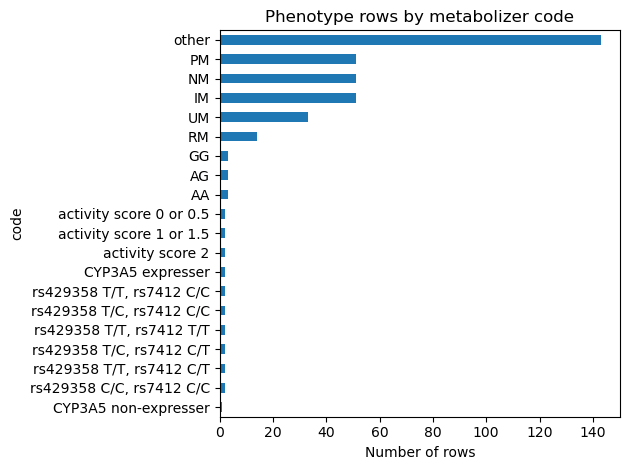

In [21]:
codes = phen["code"].value_counts().sort_values()
ax = codes.plot.barh(title="Phenotype rows by metabolizer code")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Number of rows")
plt.tight_layout()
plt.show()

### Look up one gene

Lists every variant for a gene with its details, then summarizes the functional effects.

In [22]:
def show_gene(gene, plot=False, run_ts=None):
    """List a gene's variants with their details, then summarize the functional effects."""
    con = sqlite3.connect(DB)
    ts = run_ts or con.execute("SELECT MAX(run_ts) FROM variants").fetchone()[0]
    df = pd.read_sql(
        "SELECT v.rsid, v.name, v.alleles, v.effect, v.frequency, "
        "  (SELECT group_concat(s.source, '; ') FROM variant_sources s "
        "   WHERE s.run_ts = v.run_ts AND s.rsid = v.rsid AND s.gene = v.gene) AS sources "
        "FROM variants v WHERE v.run_ts = ? AND UPPER(v.gene) = UPPER(?) "
        "ORDER BY v.name, v.rsid",
        con, params=(ts, gene))
    known = [r[0] for r in con.execute(
        "SELECT DISTINCT gene FROM variants WHERE run_ts = ? ORDER BY gene", (ts,))]
    con.close()

    if df.empty:
        print(f"No variants stored for '{gene}'. Genes with variants: {', '.join(known)}")
        return None

    df["label"] = df["name"].fillna(df["rsid"])
    df["effect_clean"] = df["effect"].fillna("not provided")

    def fmt(v):
        return "-" if pd.isna(v) else v

    print(f"{gene.upper()}: {len(df)} variants (run {ts})\n")
    for _, r in df.iterrows():
        print(f"{r['rsid']}   {r['name'] if pd.notna(r['name']) else ''}")
        print(f"  alleles:   {fmt(r['alleles'])}")
        print(f"  effect:    {fmt(r['effect'])}")
        print(f"  frequency: {fmt(r['frequency'])}")
        print(f"  sources:   {fmt(r['sources'])}\n")

    print("Functional effects")
    counts = df["effect_clean"].value_counts()
    for effect, n in counts.items():
        labels = ", ".join(df.loc[df["effect_clean"] == effect, "label"])
        print(f"  {effect}: {n}  ({labels})")

    if plot:
        ax = counts.sort_values().plot.barh(title=f"{gene.upper()}: variants by functional effect")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_xlabel("Number of variants")
        plt.tight_layout()
        plt.show()

    return df.drop(columns=["label", "effect_clean"])


gene_df = show_gene("CYP2C19")

CYP2C19: 3 variants (run 2026-11-15T18:43:01+00:00)

rs12248560   *17 (c.-806C>T)
  alleles:   Plus strand, GRCh37 (as in 23andMe raw data): C reference, T variant (c.-806C>T), found in *17.
  effect:    -
  frequency: -
  sources:   CPIC — CYP2C19 gene page; PharmVar CYP2C19; CPIC — CYP2C19 allele frequency table; Ensembl GRCh37 rs12248560 population frequencies (1000 Genomes phase 3)

rs4244285   *2 (c.681G>A)
  alleles:   Plus strand, GRCh37 (as in 23andMe raw data): G reference, A variant, which defines *2. CYP2C19 is on the plus strand, so the letters match the gene. Copies of A at this one position are not a metabolizer status: that needs the other CYP2C19 variants and phasing.
  effect:    -
  frequency: -
  sources:   CPIC — CYP2C19 gene page; PharmVar CYP2C19

rs4986893   *3 (c.636G>A)
  alleles:   Plus strand, GRCh37 (as in 23andMe raw data): G reference, A variant (Trp212Ter), which defines *3.
  effect:    -
  frequency: -
  sources:   CPIC — CYP2C19 gene page; PharmVar CYP

## 6. Findings

- **Gene coverage:** CYP2D6 has the most drug pairs (19), and 4 genes (VKORC1, CYP3A5, CYP4F2, MTHFR) are tied for the fewest (1).
- **Evidence sources:** about 93%% (70/75) of pairs are backed by CPIC, 4% (3/75) by DPWG, and 3% (2/75) mention FDA labeling.
- **Evidence strength:** CPIC A pairs carry the strongest level; 8 pairs have no level listed.
- **Multi-gene drugs:** Many drugs depend on more than one gene, so a single gene result may not tell the whole story.
- **Variants:** DPYD and COMT have the most key variants (4).
- **Sources:** the most-cited source is pubmed.ncbi.nlm.nih.gov (114 citations).
- **Phenotypes:** pairs typically list 3 to 6 phenotype groups (4.5 on average: 373 rows across 82 pairs), and no single count dominates; 4 is the most common, at 22 pairs. PM, IM and NM are the most common metabolizer codes (51 rows each, across CYP2C19, CYP2C9, CYP2D6, NUDT15 and TPMT), followed by UM (33) and RM (14). However, 143 rows (38%) have no parsed code, mostly G6PD and SLCO1B1.
- **Gaps:** HFE returned no pairs, so coverage for this genes is limited.


## 7. Limitations

- The data is curated reference data and changes slowly, so the coverage-over-time series will look flat until the API grows.
- Results are educational and are not diagnosis, prescription, or dosing guidance.
- Coverage depends on the genes in the seed list and on what the API currently includes.

## 8. Next steps

- Schedule a weekly run (GitHub Actions or cron) to build a real history in `run_summary`
- Build a Streamlit dashboard reading `deepdna.db`
- Move the functions into `pipeline.py`, add `requirements.txt`, and write the README